# ⚖️ เปรียบเทียบ: แบบมี label (Random Forest) vs ไม่มี label (Isolation Forest)

Notebook นี้ใช้ **เปรียบเทียบเท่านั้น** — ไม่บันทึกอะไรลง `system/models/` (ระบบจริงยังใช้ Isolation Forest ตาม README)

| | Isolation Forest (ระบบจริง) | Random Forest (ตัวเปรียบเทียบ) |
|---|---|---|
| ข้อมูลเทรน | traffic ปกติอย่างเดียว (ไม่มี label) | traffic ปกติ + **การโจมตีที่ติด label** |
| เรียนรู้อะไร | "ปกติหน้าตาเป็นยังไง" → อะไรต่างไปถือว่าแปลก | "การโจมตีที่เคยเห็นหน้าตาเป็นยังไง" |
| feature | 23 ตัวเดียวกัน (`shared/features.py`) | 23 ตัวเดียวกัน |

**การแบ่งข้อมูล (ไม่ให้ชุดทดสอบรั่วเข้าชุดเทรน):**
- เทรน RF: traffic ปกติชุดเดียวกับ Isolation Forest + CIC-IDS2017 Friday **ก่อน** `FRIDAY_SPLIT` 15:00 (PortScan ~282k packets: รอบแรกช่วงเปิด firewall มีแค่ ~1.5k เพราะโดนบล็อก + ช่วงพีกของรอบสอง 14:51–14:59)
- ทดสอบทั้งสองโมเดลด้วยชุดเดียวกัน: CIC Friday **หลัง** 15:00 (PortScan ช่วงท้าย ~42k packets) + traffic จริงในบ้าน (Discord + ping/scan จาก iPhone) + ping/nmap จำลอง
- ping **ไม่มี** ในข้อมูลเทรนของ RF (CIC ไม่มี ping ที่ติด label) → ดูว่าโมเดลแบบมี label รับมือการโจมตีที่ไม่เคยเห็นได้แค่ไหน


## 0. ตั้งค่า

In [1]:
import sys, time, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "training" else Path.cwd()
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "system"))

import numpy as np
import joblib
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from matplotlib import font_manager
_fonts = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams["font.family"] = [f for f in ("Tahoma", "Leelawadee UI", "Noto Sans Thai", "Loma") if f in _fonts] or ["DejaVu Sans"]
from sklearn.ensemble import RandomForestClassifier

from shared.config import load_config, resolve_path
from shared.features import FEATURE_NAMES, FEATURE_VERSION
from training.generate_data import load_packets_csv
from training.common import build_features, anomaly_scores
from training import evaluate as ev

cfg = load_config()
T = cfg["training"]
D = cfg["detection"]

# ================= PARAMETERS (แก้ได้) =================
WINDOW_SEC     = cfg["feature"]["window_sec"]
SEED           = T["seed"]
NORMAL_CSVS    = [resolve_path(T["packets_csv"]),                                   # synthetic
                  resolve_path(T["pcap_csv_dir"]) / "normal__Monday-WorkingHours.csv",  # CIC Monday (ปกติ)
                  resolve_path("data/captured_packets.csv"),                         # traffic บ้าน
                  resolve_path("data/home_discord_normal.csv")]                      # บ้าน + Discord
FRIDAY_CSV     = resolve_path(T["pcap_csv_dir"]) / "test__Friday-WorkingHours.csv"
HOME_TEST_CSVS = [resolve_path("data/home_test_session2.csv")]
LABELS_FILE    = resolve_path(T["labels_file"])
FRIDAY_SPLIT   = "2017-07-07T15:00:00-03:00"   # ก่อนเวลานี้ = เทรน RF, หลังจากนี้ = ทดสอบ (ถ้าแบ่งที่ 14:43 RF จะเห็น PortScan แค่ ~1.5k packets)
MAX_TRAIN_PER_SOURCE = 200_000                 # สุ่มแถวต่อไฟล์ (เหมือน Isolation Forest)
RF_TREES       = 100
# =======================================================

RUN_DIR = resolve_path("results") / time.strftime("compare_%Y%m%d_%H%M%S")
RUN_DIR.mkdir(parents=True, exist_ok=True)
_REPORT = [f"# เปรียบเทียบ Random Forest (มี label) vs Isolation Forest (ไม่มี label) — {time.strftime('%Y-%m-%d %H:%M:%S')}\n"]
def report(title, text=""):
    _REPORT.append(f"## {title}\n\n{text}\n")
    (RUN_DIR / "report.md").write_text("\n".join(_REPORT), encoding="utf-8")
def save_fig(fig, name):
    fig.savefig(RUN_DIR / name, dpi=120, bbox_inches="tight")

rules = ev.load_label_rules(LABELS_FILE)
split_ts = ev.parse_time(FRIDAY_SPLIT)
rng = np.random.default_rng(SEED)
report("ตั้งค่า", f"- FRIDAY_SPLIT = {FRIDAY_SPLIT}\n- RF: {RF_TREES} trees, class_weight=balanced\n"
       f"- feature v{FEATURE_VERSION} ({len(FEATURE_NAMES)} ตัว), window {WINDOW_SEC}s\n- กฎใน labels.csv: {len(rules)} ข้อ")
print("เก็บผลที่:", RUN_DIR)


เก็บผลที่: C:\Project_AI\Project-AI-IDS\results\compare_20261113_010723


## 1. โหลดข้อมูล + คำนวณ feature
คำนวณ feature จากแต่ละไฟล์เต็มก่อน (ctx_* ต้องเห็น packet ต่อเนื่อง) แล้วค่อยแบ่ง/สุ่ม

In [2]:
def load_sorted(path, drop_echo=False):
    pk = load_packets_csv(path)
    if drop_echo:
        pk = [p for p in pk if not (p["proto"] == "ICMP" and p["icmp_type"] in (0, 8))]
    pk.sort(key=lambda p: p["ts"])
    return pk

# ---- traffic ปกติ (ชุดเดียวกับที่ Isolation Forest ใช้เทรน) -> label 0
X_norm_parts, data_rows = [], []
for path in NORMAL_CSVS:
    if not path.exists():
        print("⚠️ ข้าม (ไม่พบ):", path)
        continue
    pk = load_sorted(path, drop_echo=True)
    X = build_features(pk, WINDOW_SEC)
    if MAX_TRAIN_PER_SOURCE and len(X) > MAX_TRAIN_PER_SOURCE:
        X = X[np.sort(rng.choice(len(X), MAX_TRAIN_PER_SOURCE, replace=False))]
    X_norm_parts.append(X)
    data_rows.append({"ไฟล์": path.name, "ใช้": "เทรน RF (ปกติ)", "packets": len(X), "โจมตี": 0})

# ---- CIC Friday: แบ่งตามเวลา
fri = load_sorted(FRIDAY_CSV)
X_fri = build_features(fri, WINDOW_SEC)
names_fri = np.array(ev.label_packets(fri, rules), dtype=object)
ts_fri = np.array([p["ts"] for p in fri])
tr = ts_fri < split_ts
X_fri_tr, names_fri_tr = X_fri[tr], names_fri[tr]
data_rows.append({"ไฟล์": FRIDAY_CSV.name, "ใช้": "เทรน RF (ก่อน split)", "packets": int(tr.sum()),
                  "โจมตี": int((names_fri_tr != ev.NORMAL).sum())})
data_rows.append({"ไฟล์": FRIDAY_CSV.name, "ใช้": "ทดสอบ (หลัง split)", "packets": int((~tr).sum()),
                  "โจมตี": int((names_fri[~tr] != ev.NORMAL).sum())})

# ---- ชุดทดสอบ: Friday หลัง split / บ้าน / จำลอง
tests = {}
tests["CIC Friday (หลัง split)"] = (X_fri[~tr], names_fri[~tr])
for path in HOME_TEST_CSVS:
    if path.exists():
        pk = load_sorted(path)
        tests[f"บ้าน: {path.stem}"] = (build_features(pk, WINDOW_SEC), np.array(ev.label_packets(pk, rules), dtype=object))
        data_rows.append({"ไฟล์": path.name, "ใช้": "ทดสอบ", "packets": len(pk),
                          "โจมตี": int((tests[f"บ้าน: {path.stem}"][1] != ev.NORMAL).sum())})
Xs, ys, ns = ev.blocks_to_xy(ev.simulated_test_set(4000, SEED + 4200, WINDOW_SEC), WINDOW_SEC)
tests["จำลอง (ping + nmap)"] = (Xs, ns)
data_rows.append({"ไฟล์": "simulated", "ใช้": "ทดสอบ", "packets": len(ns), "โจมตี": int(ys.sum())})

# ---- ชุดเทรนของ RF
X_train = np.vstack(X_norm_parts + [X_fri_tr])
y_train = np.concatenate([np.zeros(sum(len(x) for x in X_norm_parts), int), (names_fri_tr != ev.NORMAL).astype(int)])
display(Markdown(ev.md_table(data_rows)))
print(f"ชุดเทรน RF: {len(y_train):,} packets | ปกติ {int((y_train == 0).sum()):,} | โจมตี {int(y_train.sum()):,}")
print("label โจมตีที่ RF ได้เห็นตอนเทรน:", sorted(set(names_fri_tr.tolist()) - {ev.NORMAL}))
report("ข้อมูล", ev.md_table(data_rows) + f"\n\nชุดเทรน RF: {len(y_train):,} packets (โจมตี {int(y_train.sum()):,})\n\n"
       f"label โจมตีที่ RF เห็นตอนเทรน: {sorted(set(names_fri_tr.tolist()) - {ev.NORMAL})}")


| ไฟล์ | ใช้ | packets | โจมตี |
|---|---|---|---|
| normal_packets.csv | เทรน RF (ปกติ) | 8000 | 0 |
| normal__Monday-WorkingHours.csv | เทรน RF (ปกติ) | 200000 | 0 |
| captured_packets.csv | เทรน RF (ปกติ) | 33160 | 0 |
| home_discord_normal.csv | เทรน RF (ปกติ) | 146497 | 0 |
| test__Friday-WorkingHours.csv | เทรน RF (ก่อน split) | 1052126 | 281787 |
| test__Friday-WorkingHours.csv | ทดสอบ (หลัง split) | 572373 | 42275 |
| home_test_session2.csv | ทดสอบ | 222254 | 964 |
| simulated | ทดสอบ | 5984 | 1984 |

ชุดเทรน RF: 1,439,783 packets | ปกติ 1,157,996 | โจมตี 281,787
label โจมตีที่ RF ได้เห็นตอนเทรน: ['PortScan']


## 2. เทรน Random Forest (มี label) + โหลด Isolation Forest ที่ระบบใช้อยู่

เทรน RF เสร็จใน 66.9s
Isolation Forest: เทรนเมื่อ 2026-11-12 22:09:40 | threshold 0.6427


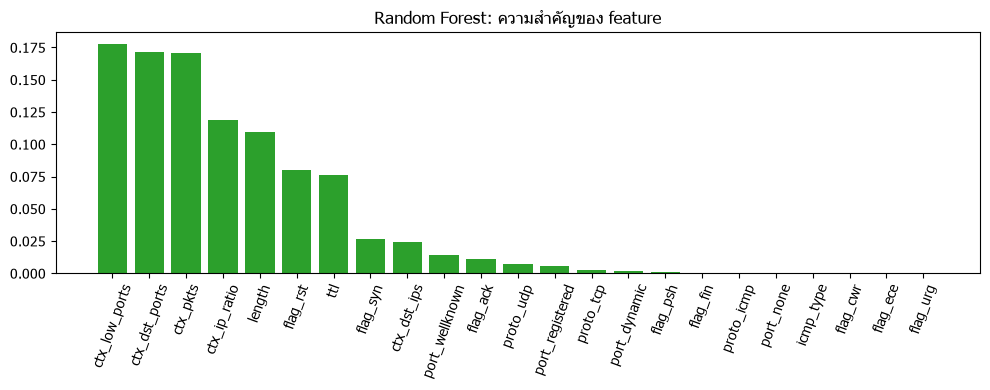

In [3]:
t0 = time.time()
rf = RandomForestClassifier(n_estimators=RF_TREES, class_weight="balanced", n_jobs=-1, random_state=SEED)
rf.fit(X_train, y_train)
print(f"เทรน RF เสร็จใน {time.time() - t0:.1f}s")

# Isolation Forest ตัวจริงของระบบ (system/models) + threshold แบบเดียวกับ detection-service
iforest = joblib.load(resolve_path(D["model_path"]))
scaler = joblib.load(resolve_path(D["scaler_path"]))
meta = json.loads(resolve_path(D["meta_path"]).read_text(encoding="utf-8"))
thr_cfg = D.get("threshold", "auto")
IF_THR = float(meta["recommended_threshold"]) if str(thr_cfg).lower() == "auto" else float(thr_cfg)
print(f"Isolation Forest: เทรนเมื่อ {meta.get('trained_at')} | threshold {IF_THR:.4f}")

imp = sorted(zip(FEATURE_NAMES, rf.feature_importances_), key=lambda t: -t[1])
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar([n for n, _ in imp], [v for _, v in imp], color="tab:green")
ax.set_title("Random Forest: ความสำคัญของ feature"); ax.tick_params(axis="x", rotation=70)
fig.tight_layout(); save_fig(fig, "rf_feature_importance.png"); plt.show()
report("โมเดล", f"- RF เทรน {time.time() - t0:.1f}s\n- Isolation Forest: เทรน {meta.get('trained_at')}, threshold {IF_THR:.4f}\n\n"
       "![](rf_feature_importance.png)\n\nfeature สำคัญสุด 5 อันดับของ RF: " + ", ".join(f"{n} ({v:.3f})" for n, v in imp[:5]))


## 3. ผลบนชุดทดสอบเดียวกัน

### สรุปต่อชุดทดสอบ
| ชุดทดสอบ | โมเดล | Recall | FPR | Precision | F1 | FP | FN |
|---|---|---|---|---|---|---|---|
| CIC Friday (หลัง split) | Isolation Forest | 0.5300 | 0.0527 | 0.4453 | 0.4839 | 27916 | 19869 |
| CIC Friday (หลัง split) | Random Forest | 0.9724 | 0.0000 | 0.9994 | 0.9858 | 23 | 1165 |
| บ้าน: home_test_session2 | Isolation Forest | 0.9896 | 0.0000 | 1.0000 | 0.9948 | 0 | 10 |
| บ้าน: home_test_session2 | Random Forest | 0.0705 | 0.0000 | 1.0000 | 0.1318 | 0 | 896 |
| จำลอง (ping + nmap) | Isolation Forest | 0.8962 | 0.0045 | 0.9900 | 0.9407 | 18 | 206 |
| จำลอง (ping + nmap) | Random Forest | 0.6542 | 0.0000 | 1.0000 | 0.7910 | 0 | 686 |

### แยกตามประเภท (normal = อัตรา alert หลอก, อื่นๆ = อัตราที่จับได้)
| ชุดทดสอบ | label | packets | วัด | Isolation Forest | Random Forest |
|---|---|---|---|---|---|
| CIC Friday (หลัง split) | normal | 530098 | alert หลอก | 0.0527 | 0.0000 |
| CIC Friday (หลัง split) | PortScan | 42275 | จับได้ | 0.5300 | 0.9724 |
| บ้าน: home_test_session2 | normal | 221290 | alert หลอก | 0.0000 | 0.0000 |
| บ้าน: home_test_session2 | Ping-iPhone | 12 | จับได้ | 1.0000 | 0.0000 |
| บ้าน: home_test_session2 | PortScan-Fing | 952 | จับได้ | 0.9895 | 0.0714 |
| จำลอง (ping + nmap) | normal | 4000 | alert หลอก | 0.0045 | 0.0000 |
| จำลอง (ping + nmap) | nmap: nmap -sS 100 port | 100 | จับได้ | 0.9200 | 1.0000 |
| จำลอง (ping + nmap) | nmap: nmap -sS 1000 port | 1000 | จับได้ | 0.9920 | 0.9990 |
| จำลอง (ping + nmap) | nmap: nmap -sS ไล่ host (port 22 x100) | 100 | จับได้ | 0.9800 | 0.0100 |
| จำลอง (ping + nmap) | nmap: nmap -sT (connect) 200 port | 200 | จับได้ | 0.9550 | 0.9750 |
| จำลอง (ping + nmap) | nmap: nmap -sU (UDP) 100 port | 100 | จับได้ | 0.6200 | 0.0100 |
| จำลอง (ping + nmap) | nmap: nmap -sn ไล่ host (ping sweep) | 400 | จับได้ | 0.6475 | 0.0050 |
| จำลอง (ping + nmap) | ping: ping จากเครื่อง Linux/Mac | 8 | จับได้ | 1.0000 | 0.0000 |
| จำลอง (ping + nmap) | ping: ping จากเครื่อง Windows | 8 | จับได้ | 1.0000 | 0.0000 |
| จำลอง (ping + nmap) | ping: ping ตัวเอง (loopback, Windows) | 8 | จับได้ | 1.0000 | 0.0000 |
| จำลอง (ping + nmap) | ping: ping รัว (flood เล็กน้อย) | 60 | จับได้ | 1.0000 | 0.0000 |

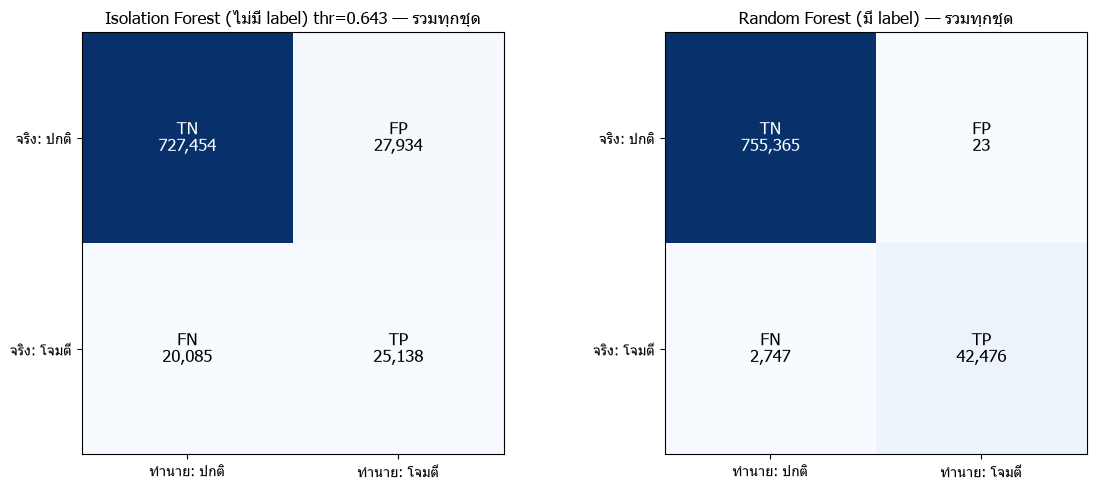

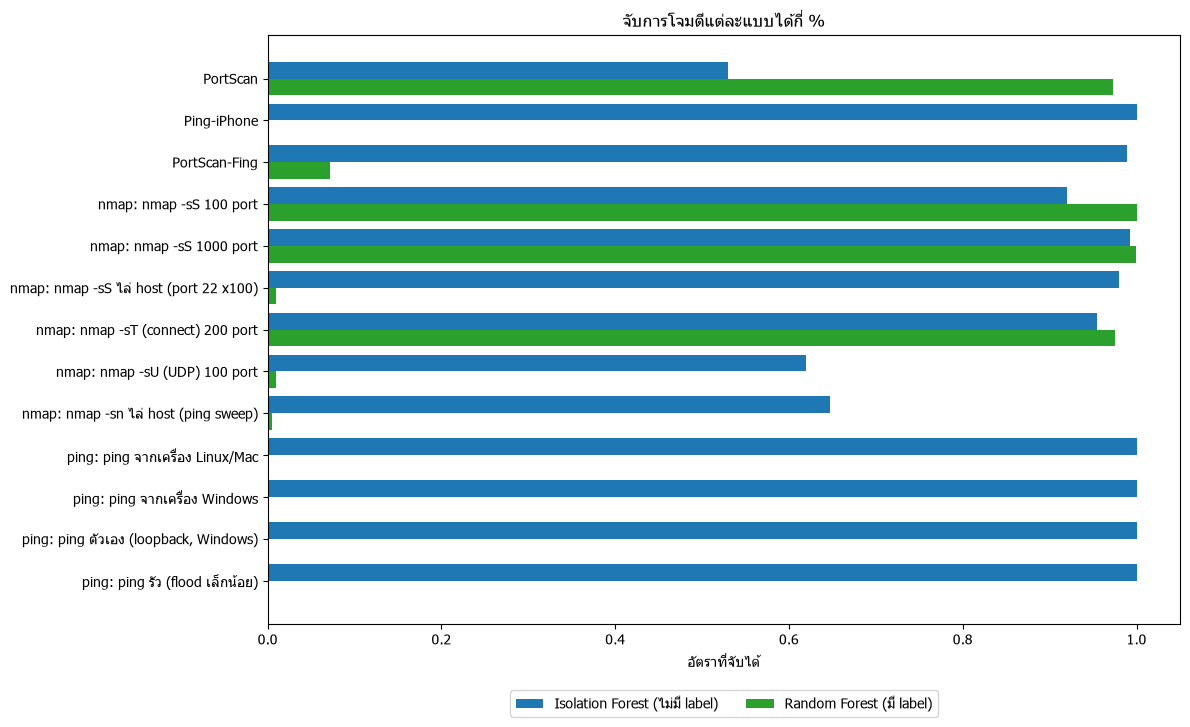

ผลทั้งหมด (รูป + report.md): C:\Project_AI\Project-AI-IDS\results\compare_20261113_010723


In [4]:
def predict_both(X):
    return (anomaly_scores(iforest, scaler, X) >= IF_THR).astype(int), rf.predict(X)

summary, label_rows, all_y, all_if, all_rf = [], [], [], [], []
for tname, (X, names) in tests.items():
    y = (names != ev.NORMAL).astype(int)
    p_if, p_rf = predict_both(X)
    all_y.append(y); all_if.append(p_if); all_rf.append(p_rf)
    for model, p in (("Isolation Forest", p_if), ("Random Forest", p_rf)):
        m = ev.binary_metrics(y, p)
        summary.append({"ชุดทดสอบ": tname, "โมเดล": model, "Recall": m["Recall (TPR)"], "FPR": m["FPR"],
                        "Precision": m["Precision"], "F1": m["F1"], "FP": m["FP"], "FN": m["FN"]})
    r_if = {r["label"]: r for r in ev.per_label_table(names, p_if)}
    r_rf = {r["label"]: r for r in ev.per_label_table(names, p_rf)}
    for lab in r_if:
        kind = "alert หลอก" if lab == ev.NORMAL else "จับได้"
        label_rows.append({"ชุดทดสอบ": tname, "label": lab, "packets": r_if[lab]["packets"], "วัด": kind,
                           "Isolation Forest": r_if[lab]["อัตรา"], "Random Forest": r_rf[lab]["อัตรา"]})

y_all, if_all, rf_all = map(np.concatenate, (all_y, all_if, all_rf))
m_if, m_rf = ev.binary_metrics(y_all, if_all), ev.binary_metrics(y_all, rf_all)
display(Markdown("### สรุปต่อชุดทดสอบ\n" + ev.md_table(summary)))
display(Markdown("### แยกตามประเภท (normal = อัตรา alert หลอก, อื่นๆ = อัตราที่จับได้)\n" + ev.md_table(label_rows)))
report("สรุปต่อชุดทดสอบ", ev.md_table(summary))
report("แยกตามประเภท", "(normal = อัตรา alert หลอก ยิ่งต่ำยิ่งดี | การโจมตี = อัตราที่จับได้ ยิ่งสูงยิ่งดี)\n\n" + ev.md_table(label_rows))
report("รวมทุกชุด (ระวัง: ตัวเลขนี้ถูกครอบงำด้วย CIC Friday ที่มี packet มากที่สุด ดูผลแยกชุดข้างบนประกอบ)", ev.md_table([{"โมเดล": "Isolation Forest", **{k: m_if[k] for k in ("Recall (TPR)", "FPR", "Precision", "F1", "TP", "FP", "TN", "FN")}},
                                   {"โมเดล": "Random Forest", **{k: m_rf[k] for k in ("Recall (TPR)", "FPR", "Precision", "F1", "TP", "FP", "TN", "FN")}}]))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ev.plot_confusion(m_if, axes[0], f"Isolation Forest (ไม่มี label) thr={IF_THR:.3f} — รวมทุกชุด")
ev.plot_confusion(m_rf, axes[1], "Random Forest (มี label) — รวมทุกชุด")
fig.tight_layout(); save_fig(fig, "confusion_if_vs_rf.png"); plt.show()

attack_rows = [r for r in label_rows if r["label"] != ev.NORMAL]
fig, ax = plt.subplots(figsize=(12, 0.45 * len(attack_rows) + 1.5))
yy = np.arange(len(attack_rows))
ax.barh(yy - 0.2, [r["Isolation Forest"] for r in attack_rows], 0.4, label="Isolation Forest (ไม่มี label)", color="tab:blue")
ax.barh(yy + 0.2, [r["Random Forest"] for r in attack_rows], 0.4, label="Random Forest (มี label)", color="tab:green")
ax.set_yticks(yy, [r["label"] for r in attack_rows]); ax.invert_yaxis()
ax.set_xlabel("อัตราที่จับได้"); ax.set_xlim(0, 1.05); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2); ax.set_title("จับการโจมตีแต่ละแบบได้กี่ %")
fig.tight_layout(); save_fig(fig, "detection_by_attack.png"); plt.show()
report("กราฟ", "![](confusion_if_vs_rf.png)\n\n![](detection_by_attack.png)")
(RUN_DIR / "metrics.json").write_text(json.dumps({"isolation_forest": m_if, "random_forest": m_rf, "per_test": summary,
                                                  "per_label": label_rows}, ensure_ascii=False, indent=2, default=float), encoding="utf-8")
print("ผลทั้งหมด (รูป + report.md):", RUN_DIR)


> **อ่านผลอย่างไร**
> - ชุด **CIC Friday** มาจากเครือข่ายเดียวกับที่ RF ใช้เทรน และเป็นการโจมตีแบบเดียวกัน → RF มักได้คะแนนสูงมาก
> - ชุด **บ้าน** และ **ping จำลอง** คือสิ่งที่ RF **ไม่เคยเห็น** (เครือข่ายอื่น / การโจมตีชนิดอื่น) → ใช้วัดว่าโมเดลแต่ละแบบรับมือของใหม่ได้ไหม
> - โมเดลแบบมี label ตรวจได้เฉพาะสิ่งที่มีใน label ตอนเทรน ส่วนแบบไม่มี label ตรวจ "อะไรที่ไม่เหมือนปกติ" จึงจับของใหม่ได้ แต่แลกกับ alert หลอกที่มากกว่าเมื่อเจอ traffic ปกติแบบที่ไม่เคยเห็น
